# Registry: publicação, aprovação e consumo

25 minutos

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

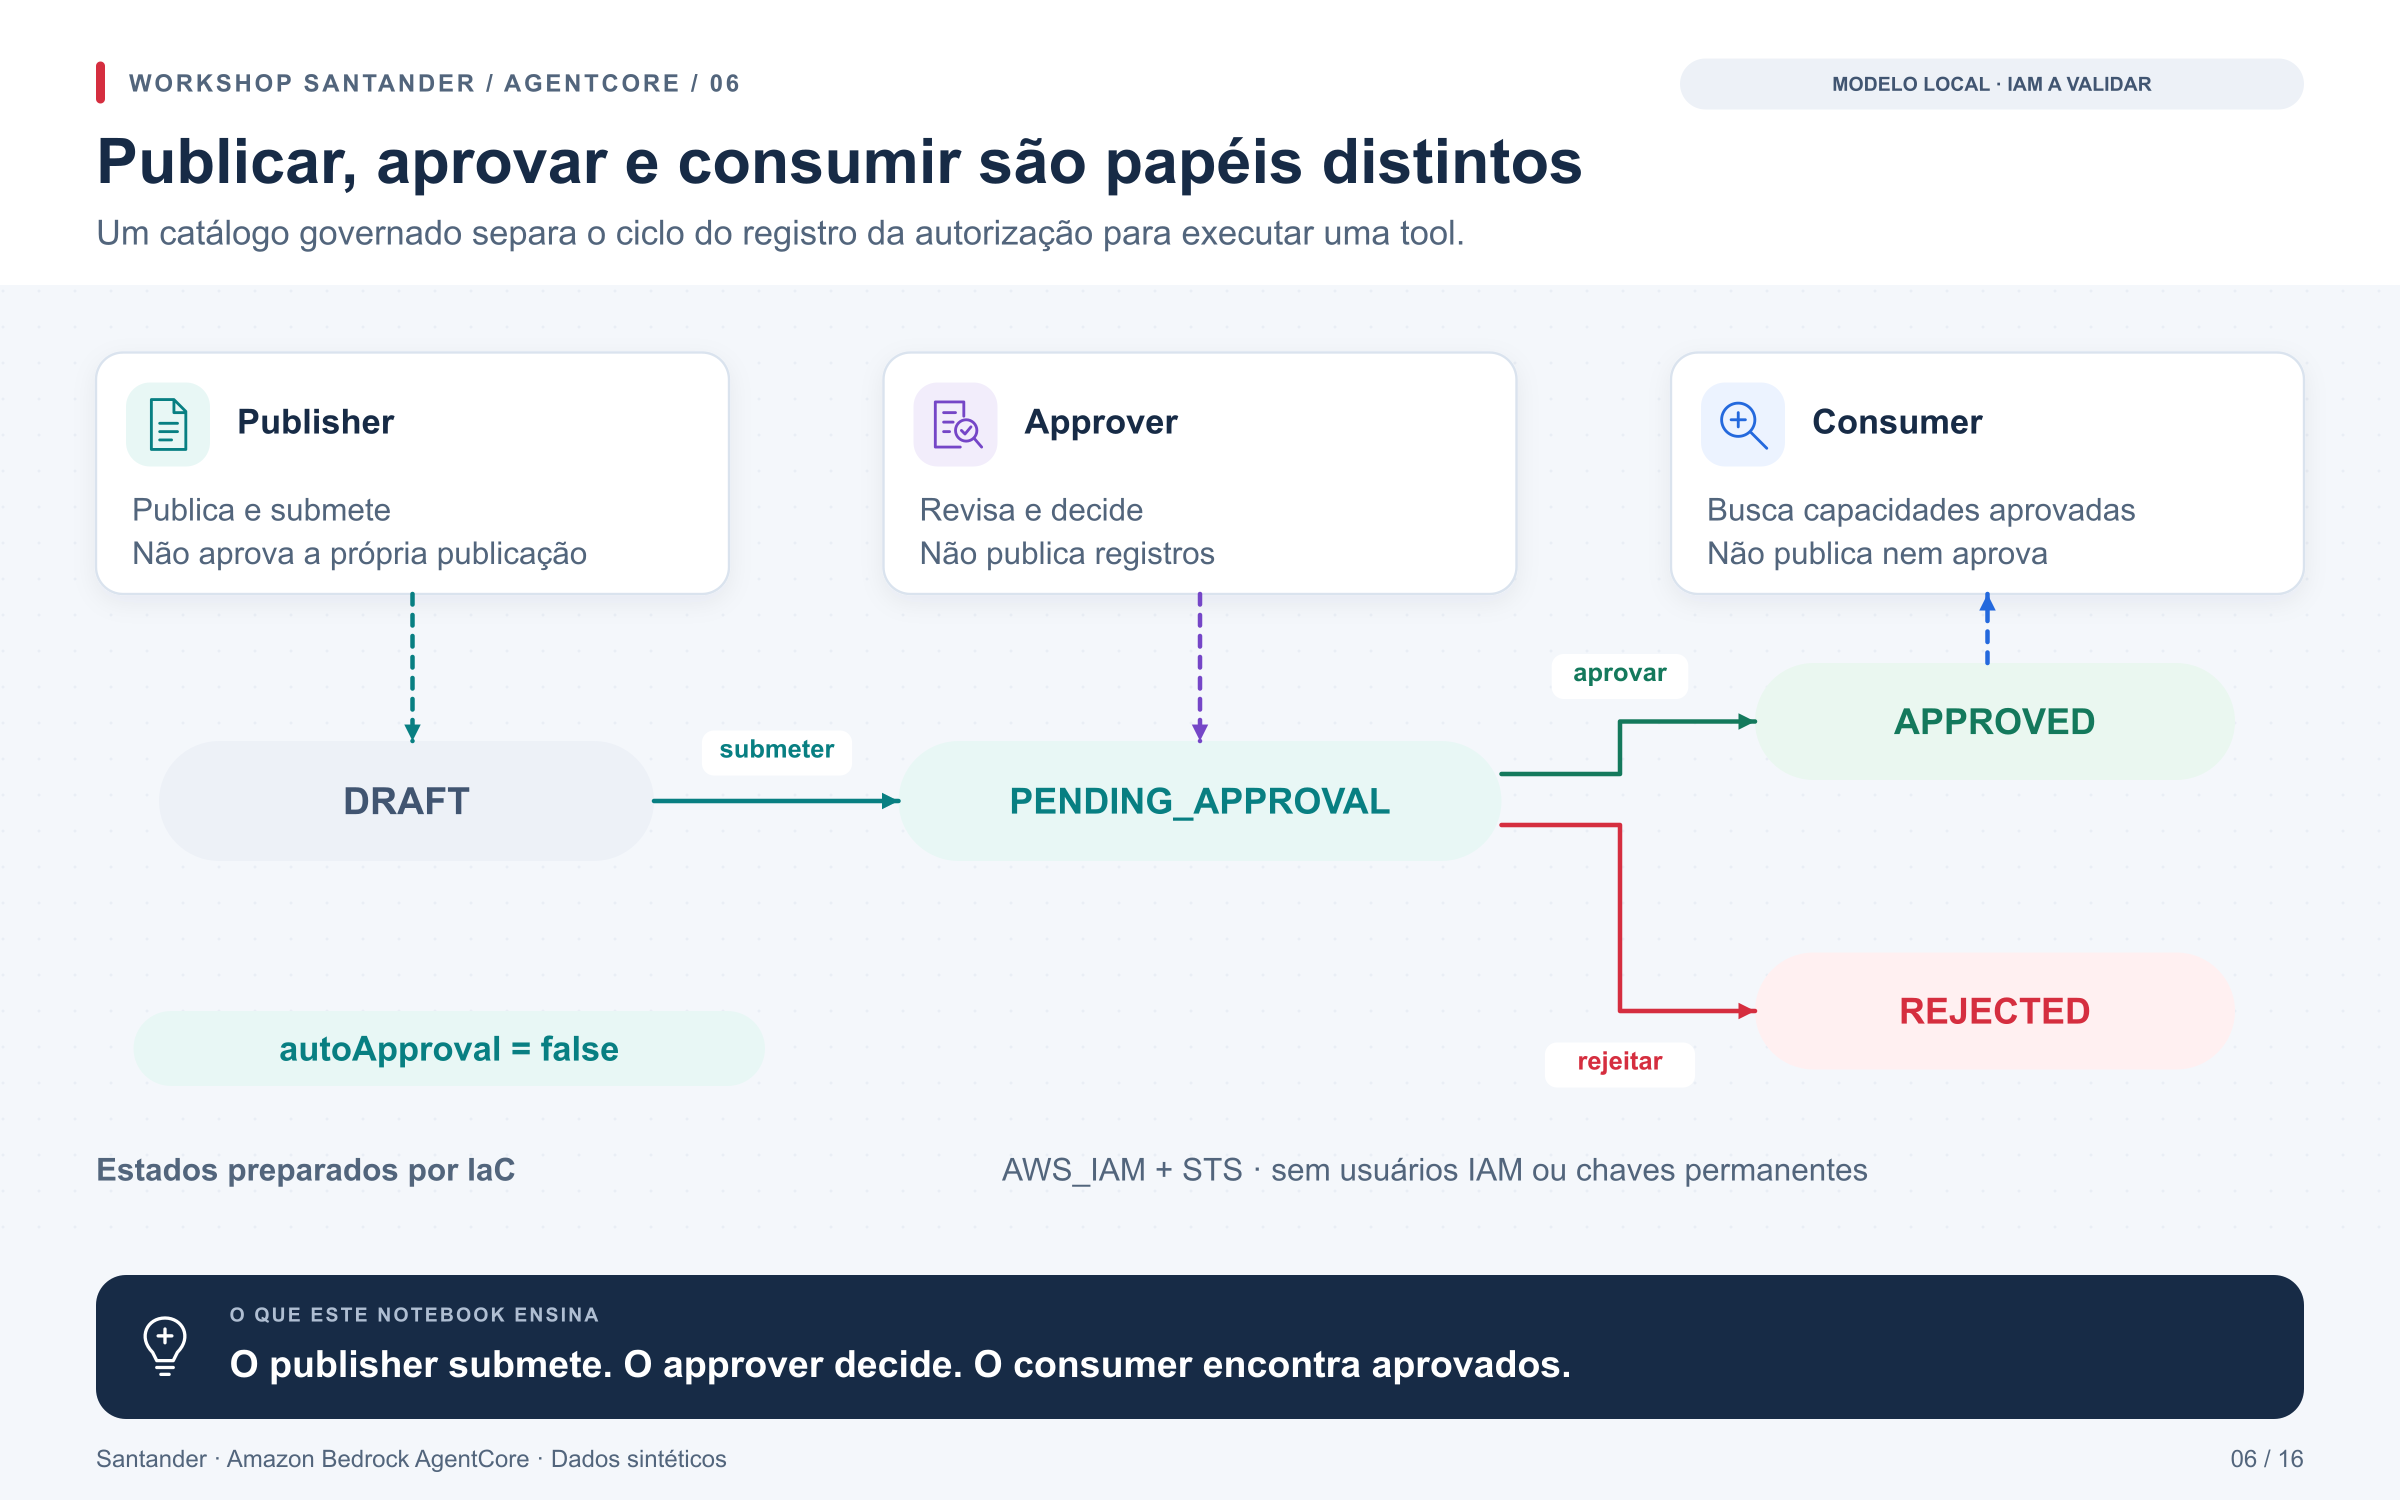

**Objetivo visual:** Verificar a separação de papéis e observar todos os estados preparados para o workshop.

[Abrir PNG](../docs/diagramas/png/06_registry_governanca.png) · [SVG editável](../docs/diagramas/svg/06_registry_governanca.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 7 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Autoria de políticas](05_policy_autoria.ipynb) · [Próximo: Ciclo de vida com quatro personas](07_registry_personas.ipynb)

## Conceitos para acompanhar este laboratório

**Registry** é um catálogo de metadados de capacidades. Um registro descreve
uma ferramenta ou servidor; ele não armazena uma permissão para executar
qualquer coisa publicada ali.

Neste contrato, o **publicador** cria e submete; o **aprovador** decide;
o **consumidor** pesquisa registros aprovados. Os estados usados são
`DRAFT` → `PENDING_APPROVAL` → `APPROVED` ou `REJECTED`.
Desativar aprovação automática separa publicação de disponibilidade na busca.

[registry.py](../src/santander_demo/registry.py) simula esses papéis com
strings em memória. Na AWS, a separação depende de roles e políticas IAM,
com credenciais temporárias do STS. O teste local de papel não comprova
que as permissões IAM do ambiente estão corretas.

**Documentação oficial para aprofundar:**

* [Conceitos do AWS Agent Registry](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/registry.html)
* [Revisão e aprovação de registros](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/registry-reviewing-records.html)
* [Pesquisa de registros](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/registry-search-records.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

O laboratório usa Registry com busca AWS_IAM, sessões STS e autoApproval=false.
Entra autentica o Gateway; não é usado como authorizer do Registry nesta variante.
Publisher publica/submete; Approver aprova/rejeita; Consumer busca.

No modo AWS, os estados são preparados por recursos de CloudFormation. As
operações de publicação abaixo alteram apenas o modelo em memória.

### Percorrer publicação, submissão e aprovação local

Vamos criar o registro `exercicio` no catálogo em memória e submetê-lo
como `publisher`. Em seguida, tentaremos aprová-lo com esse mesmo
papel e esperaremos `REGISTRY_APPROVAL_DENIED`. A aprovação será
repetida como `approver`, após o que uma busca deverá encontrar a proposta.
Também verificaremos que ela fica invisível na busca enquanto
estiver em `DRAFT` ou `PENDING_APPROVAL`.

A saída mostrará os estados dos registros locais e permitirá observar
a separação de responsabilidades. Esta célula sempre usa `lab.registry`;
para repetir o exercício desde o início, reexecute a preparação do ambiente.

In [ ]:
from santander_demo.registry import Record
registry = lab.registry
registry.publish(Record("exercicio", "demo", "proposta de capacidade"), "publisher")
assert registry.records["exercicio"].state == "DRAFT"
assert not registry.search("proposta")
registry.submit("exercicio", "publisher")
assert registry.records["exercicio"].state == "PENDING_APPROVAL"
assert not registry.search("proposta")
try:
    registry.decide("exercicio", "APPROVED", "publisher")
    raise AssertionError("Publisher aprovou a própria publicação")
except DemoError as exc:
    assert exc.code == "REGISTRY_APPROVAL_DENIED"
assert registry.records["exercicio"].state == "PENDING_APPROVAL"
registry.decide("exercicio", "APPROVED", "approver")
assert [record["name"] for record in registry.search("proposta")] == ["exercicio"]
print({"mode": "LOCAL_SIMULATION", "states": {k: r.state for k, r in registry.records.items()}})

### Consultar os estados existentes no Registry AWS

No modo AWS, vamos listar os registros do Registry configurado e
verificar se o conjunto inclui `DRAFT`, `PENDING_APPROVAL`, `APPROVED`
e `REJECTED`, preparados anteriormente pelo CloudFormation.

Esperamos ver os nomes e estados dos registros. Se algum dos quatro
estados estiver ausente, a asserção falhará. No modo local, esta
célula não fará consultas e mostrará `aws_registry_states: NOT_RUN`.

In [ ]:
if MODE == "aws":
    states = cloud.registry_states()
    assert {"DRAFT", "PENDING_APPROVAL", "APPROVED", "REJECTED"} <= {r["status"] for r in states}
    print(states)
else:
    print({"aws_registry_states": "NOT_RUN"})

**Gate IAM:** validar permissões dos três roles com `iam simulate-principal-policy`
(read-only) e revisar as trust policies. Não criar usuários/chaves para o workshop.
O provider de publicação não tem `UpdateRegistryRecordStatus`; o de aprovação
não tem `CreateRegistryRecord`. Aprovação de um registro não autoriza a tool.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'identity', 'lab', 'registry', 'states', 'token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json